### Парсинг пресс-релизов

Важно различать два понятия: публикация, посвящённая ключевой ставке, и пресс-релиз с решением по ключевой ставке. Фильтр API по теме не гарантирует, что каждая запись содержит решение по ставке; поэтому релевантность дополнительно проверяется по заголовку и тексту.


In [1]:
pip install work-calendar
import json
import time
from datetime import date
from bs4 import BeautifulSoup
from curl_cffi import requests
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates

INLINE_TAGS = ["strong", "b", "i", "em", "u", "span", "a", "sup", "sub", "mark"]
BLOCK_TAGS = ["p", "div", "li", "tr", "h1", "h2", "h3", "h4", "h5", "h6", "blockquote"]

BASE = "https://www.cbr.ru"
IMPERSONATE = "chrome124"
TIMEOUT = 10
RETRIES = 3
SLEEP_BETWEEN_REQUESTS = 2.0
SLEEP_BETWEEN_RELEASES = 7.0

HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 "
        "(KHTML, like Gecko) Chrome/124.0.0.0 Safari/537.36"
    ),
    "Accept": (
        "text/html,application/xhtml+xml,application/xml;q=0.9,"
        "image/avif,image/webp,*/*;q=0.8"
    ),
    "Accept-Language": "ru-RU,ru;q=0.9,en;q=0.8",
    "Sec-Fetch-Dest": "document",
    "Sec-Fetch-Mode": "navigate",
    "Sec-Fetch-Site": "none",
    "Upgrade-Insecure-Requests": "1",
}


def _get(url, **kwargs):
    """GET с ретраями и таймаутом."""
    for attempt in range(RETRIES):
        try:
            res = requests.get(
                url,
                impersonate=IMPERSONATE,
                timeout=TIMEOUT,
                headers=HEADERS,
                default_headers=True,
                **kwargs,
            )
            res.raise_for_status()
            return res
        except Exception as e:
            if attempt == RETRIES - 1:
                raise
            print(f"Попытка {attempt + 1} не удалась: {e}")
            time.sleep(SLEEP_BETWEEN_REQUESTS * (attempt + 1))

def get_press_releases(page=0):
    """Получает список пресс-релизов по ключевой ставке через API ЦБ."""
    url = f"{BASE}/news/eventandpress/"
    params = {
        "page": page,
        "IsEng": "false",
        "type": 4,  # тип события: пресс-релизы
        "dateFrom": "1991-01-23T00:00:00",
        "dateTo": date.today().isoformat(),  # динамическая дата
        "Tid": 0,
        "vol": "KEYRATE",  # тема: ключевая ставка
        "phrase": "",
        "pagesize": 40,
    }

    res = _get(url, params=params)
    content_type = res.headers.get("Content-Type", "")
    if "application/json" not in content_type:
        raise ValueError(f"Unexpected content-type: {content_type}")

    data = res.json()

    # Поддержка двух форматов ответа: {"items": [...], "total": N} или плоский список
    if isinstance(data, dict):
        items = data.get("items", [])
        total = data.get("total", 0)
        return items, total
    if isinstance(data, list):
        return data, len(data)

    raise ValueError(f"Unknown response structure: {type(data)}")


def press_release_url(file_name):
    """Собирает URL страницы пресс-релиза по имени файла."""
    return f"{BASE}/press/pr/?file={file_name}"


def parse_press_page(file_name):
    url = press_release_url(file_name)
    res = _get(url)
    soup = BeautifulSoup(res.text, "html.parser")
    body = soup.select_one(".news_text, .content, #content")
    if body is None:
        raise ValueError(f"Content block not found for {file_name}")

    for tag in body.find_all(INLINE_TAGS):
        tag.unwrap()

    for br in body.find_all("br"):
        br.replace_with(" ")

    for block in body.find_all(BLOCK_TAGS):
        block.insert_after(" ")

    text = body.get_text()
    text = re.sub(r"\s+", " ", text).strip()
    return text


def collect_all_releases(sleep=SLEEP_BETWEEN_RELEASES):
    """Собирает все пресс-релизы, идя по страницам, пока не встретит пустую."""
    all_releases = []
    seen_files = set()
    page = 0

    while True:
        items, _total = get_press_releases(page=page)

        if not items:
            print(f"Страница {page}: пусто, завершаю")
            break

        print(f"Страница {page}: {len(items)} записей")

        for item in items:
            file_name = item["doc_htm"]
            if file_name in seen_files:
                continue
            seen_files.add(file_name)

            release = {
                "title": item["name_doc"].replace("\xa0", " "),
                "date": item["dateupdate"],
                "url": press_release_url(file_name),
            }

            try:
                release["text"] = parse_press_page(file_name)
            except Exception as e:
                print(f"  ⚠️ не удалось загрузить {file_name}: {e}")
                release["text"] = ""

            all_releases.append(release)
            time.sleep(sleep)

        page += 1

    print(f"\nВсего собрано: {len(all_releases)}")
    return all_releases


In [2]:
releases = collect_all_releases()

df = pd.DataFrame(releases)
print(df.head())

Страница 0: 20 записей
Страница 1: 20 записей
Страница 2: 20 записей
Страница 3: 20 записей
Страница 4: 20 записей
Страница 5: 16 записей
Страница 6: пусто, завершаю

Всего собрано: 116
                                               title                 date  \
0  Банк России принял решение сохранить ключевую ...  2026-09-11T13:30:00   
1  Банк России принял решение снизить ключевую ст...  2026-07-24T13:30:00   
2  Банк России принял решение снизить ключевую ст...  2026-06-19T13:30:00   
3  Банк России принял решение снизить ключевую ст...  2026-04-24T13:30:00   
4  Банк России принял решение снизить ключевую ст...  2026-03-20T13:30:00   

                                                 url  \
0  https://www.cbr.ru/press/pr/?file=11092026_133...   
1  https://www.cbr.ru/press/pr/?file=24072026_133...   
2  https://www.cbr.ru/press/pr/?file=19062026_133...   
3  https://www.cbr.ru/press/pr/?file=24042026_133...   
4  https://www.cbr.ru/press/pr/?file=20032026_133...   

              

In [5]:
df

,title,date,url,text,title_norm
0,Банк России принял решение сохранить ключевую ...,2026-09-11 13:30:00.000,https://www.cbr.ru/press/pr/?file=11092026_133...,Совет директоров Банка России 11 сентября 2026...,Банк России принял решение сохранить ключевую ...
1,Банк России принял решение снизить ключевую ст...,2026-07-24 13:30:00.000,https://www.cbr.ru/press/pr/?file=24072026_133...,Совет директоров Банка России 24 июля 2026 год...,Банк России принял решение снизить ключевую ст...
2,Банк России принял решение снизить ключевую ст...,2026-06-19 13:30:00.000,https://www.cbr.ru/press/pr/?file=19062026_133...,Совет директоров Банка России 19 июня 2026 год...,Банк России принял решение снизить ключевую ст...
3,Банк России принял решение снизить ключевую ст...,2026-04-24 13:30:00.000,https://www.cbr.ru/press/pr/?file=24042026_133...,Совет директоров Банка России 24 апреля 2026 г...,Банк России принял решение снизить ключевую ст...
4,Банк России принял решение снизить ключевую ст...,2026-03-20 13:30:00.000,https://www.cbr.ru/press/pr/?file=20032026_133...,Совет директоров Банка России 20 марта 2026 го...,Банк России принял решение снизить ключевую ст...
...,...,...,...,...,...
111,О ключевой ставке Банка России,2013-12-13 13:27:25.040,https://www.cbr.ru/press/pr/?file=131213_13300...,Новости О ключевой ставке Банка России 13 дека...,О ключевой ставке Банка России
112,О ключевой ставке Банка России,2013-11-08 10:27:31.673,https://www.cbr.ru/press/pr/?file=131108_13300...,Новости О ключевой ставке Банка России 8 ноябр...,О ключевой ставке Банка России
113,О ключевой ставке Банка России,2013-10-14 11:05:21.793,https://www.cbr.ru/press/pr/?file=131014_13300...,Новости О ключевой ставке Банка России 14 октя...,О ключевой ставке Банка России
114,О системе процентных инструментов денежно-кред...,2013-09-13 09:33:52.897,https://www.cbr.ru/press/pr/?file=130913_13504...,Новости О системе процентных инструментов дене...,О системе процентных инструментов денежно-кред...


### Предобработка

На данном этапе удаляются публикации, которые попали в выдачу по теме ключевой ставки, но не описывают решение по ключевой ставке.
Далее из текста удаляются элементы интерфейса сайта и повторяющиеся служебные фрагменты (например, блоки «Поделиться» и «Сохранить в PDF»).


In [81]:
df["date"] = pd.to_datetime(df["date"], errors="coerce", format="mixed")

# Убираем 5 нерелевантных публикаций по title + date
exclude_pairs = [
    ("2015-12-29", "О фиксированном времени публикации ключевой информации по статистике внешнего сектора"),
    ("2015-09-11", "О публикации ежемесячной оценки ключевых агрегатов платежного баланса Российской Федерации"),
    ("2015-05-06", "О публикации Обзора ключевых показателей некредитных финансовых организаций за 2014 год"),
    ("2013-09-13", "О системе процентных инструментов денежно-кредитной политики Банка России"),
    ("2013-09-13", "О процентных ставках по операциям Банка России"),
]
df["title_norm"] = (
    df["title"].fillna("")
    .str.replace("\u00a0", " ", regex=False)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)
date_norm = df["date"].dt.normalize()
mask_exclude = pd.Series(False, index=df.index)
for d, t in exclude_pairs:
    mask_exclude |= date_norm.eq(pd.Timestamp(d)) & df["title_norm"].eq(t)
df_clean = df.loc[~mask_exclude].copy().reset_index(drop=True)
print("Исходно:", len(df), "| исключено:", int(mask_exclude.sum()), "| осталось:", len(df_clean))


Исходно: 116 | исключено: 5 | осталось: 111


In [82]:
CUT_MARKERS = [
    r"При использовании материала",
    r"Процентные ставки по ",
    r"Сохранить в PDF",
    r"Заявление Председателя Банка России",
]

def strip_boilerplate(s: str) -> str:
    if not isinstance(s, str):
        return ""
    # префикс + share-блок
    s = re.sub(r"^\s*Новости\s+", "", s, flags=re.I)
    s = re.sub(r"\bПресс-релиз\b", " ", s)
    s = re.sub(r"Поделиться\s+ВКонтакте\s+Telegram\s+Макс", " ", s)

    # обрезаем по самому раннему boilerplate-маркеру
    cut = len(s)
    for pat in CUT_MARKERS:
        m = re.search(pat, s)
        if m and m.start() < cut:
            cut = m.start()
    s = s[:cut]

    # нормализация
    s = re.sub(r"\s+", " ", s).strip()
    return s

df_clean["text_clean"] = df_clean["text"].apply(strip_boilerplate)

### Анализ длины и кол-ва пресс-релизов

Детальнее посмотрим на сам корпус пресс-релизов.


In [83]:
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

df_clean = df_clean.sort_values("date").reset_index(drop=True)
df_clean["year"] = df_clean["date"].dt.year
df_clean["month"] = df_clean["date"].dt.month
df_clean["weekday"] = df_clean["date"].dt.dayofweek
df_clean["len_chars"] = df_clean["text_clean"].str.len()
df_clean["len_words"] = df_clean["text_clean"].str.split().apply(len)
df_clean["days_since_prev"] = (df_clean["date"].diff().dt.days)

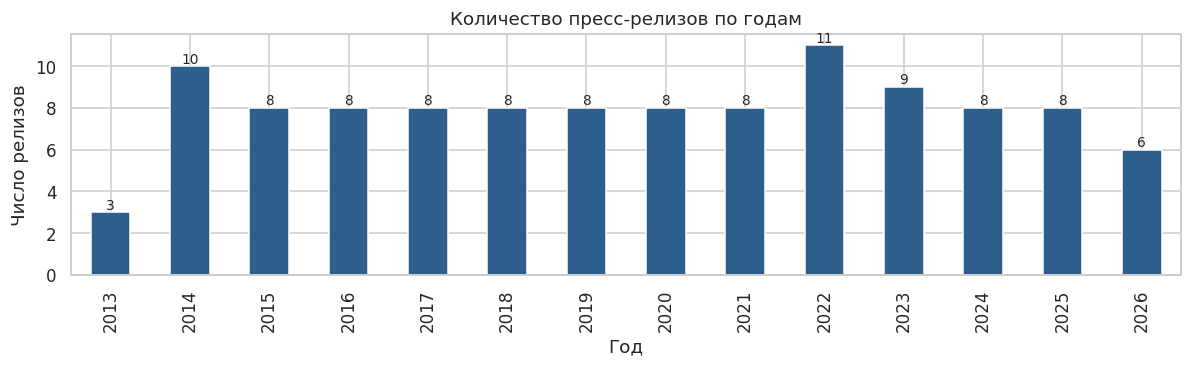

In [84]:
# Кол-во релизов по годам

per_year = df_clean.groupby("year").size()
fig, ax = plt.subplots(figsize=(11, 3.5))
per_year.plot(kind="bar", ax=ax, color="#2E5E8C")
ax.set_title("Количество пресс-релизов по годам")
ax.set_xlabel("Год")
ax.set_ylabel("Число релизов")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

Стандартно проводится 8 заседаний в год. Отклонения (10 в 2014, 11 в 2022, 9 в 2023) соответствуют периодам кризисов и внеплановых заседаний, что свидетельствует о зависимости целевой переменной от макроэкономической эпохи.

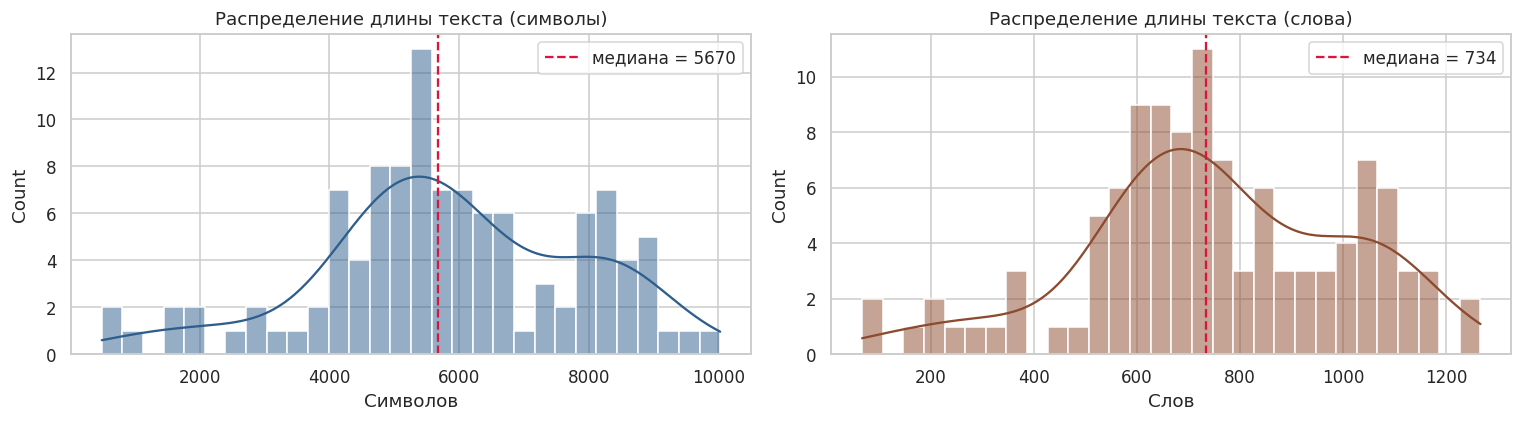

In [85]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Символы
sns.histplot(df_clean["len_chars"], bins=30, kde=True, ax=axes[0], color="#2E5E8C")
axes[0].set_title("Распределение длины текста (символы)")
axes[0].set_xlabel("Символов")
axes[0].axvline(df_clean["len_chars"].median(), color="crimson", ls="--",
                label=f"медиана = {df_clean['len_chars'].median():.0f}")
axes[0].legend()

# Слова
sns.histplot(df_clean["len_words"], bins=30, kde=True, ax=axes[1], color="#8C4A2E")
axes[1].set_title("Распределение длины текста (слова)")
axes[1].set_xlabel("Слов")
axes[1].axvline(df_clean["len_words"].median(), color="crimson", ls="--",
                label=f"медиана = {df_clean['len_words'].median():.0f}")
axes[1].legend()

plt.tight_layout()
plt.show()


Распределение двухмодальное, в корпусе смешано два формата текстов. Медиана — 5670 символов (734 слова).

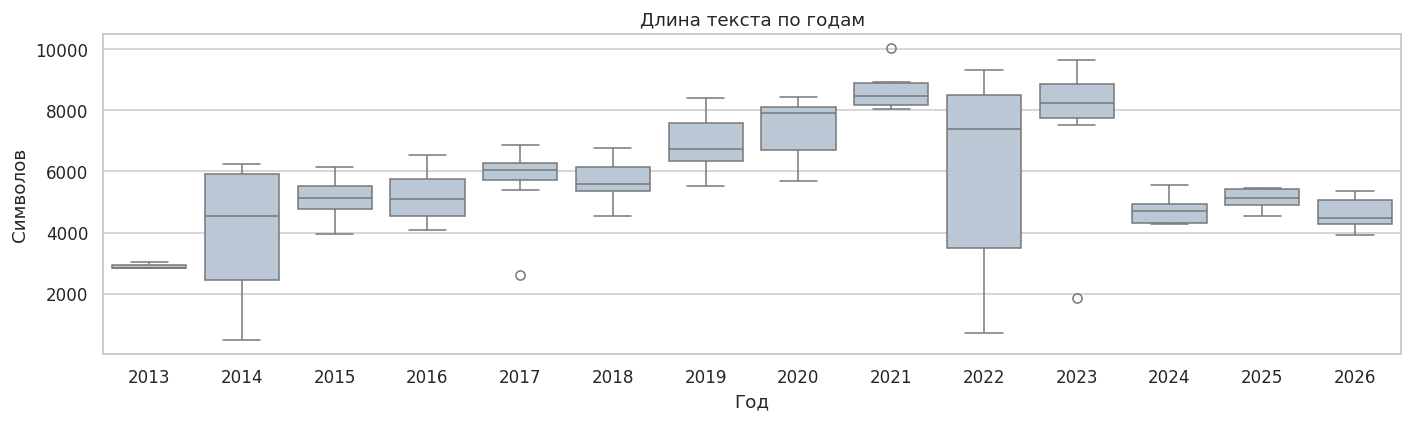

In [86]:
fig, ax = plt.subplots(figsize=(13, 4))
sns.boxplot(data=df_clean, x="year", y="len_chars", ax=ax, color="#B5C7DA")
ax.set_title("Длина текста по годам")
ax.set_xlabel("Год")
ax.set_ylabel("Символов")
plt.tight_layout()
plt.show()


Прослеживается временной тренд длины текста:

С 2013 по 2021 год тексты постепенно становились всё длиннее (от 3000 до 8000+ символов).

В 2022 году случился огромный разброс (boxplot очень широкий) — были и экстренные короткие релизы (~1000 символов), и стандартные длинные.

С 2023 года формат резко изменился: тексты стали короче и стабильнее (~4000–5000 символов).

### Получение таргета

На этом этапе формируется целевая переменная `target_next`: направление изменения ключевой ставки на следующем заседании относительно текущего уровня.

In [87]:
# Загружаем ставки ЦБ

url = (
    "https://www.cbr.ru/hd_base/KeyRate/"
    "?UniDbQuery.Posted=True"
    "&UniDbQuery.From=17.09.2013"
    "&UniDbQuery.To=20.10.2026"
)

tables = pd.read_html(url, decimal=",", thousands=".")
df_rates = tables[0].copy()

date_str = (
    df_rates["Дата"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.strip()
    .str.zfill(8)
)

df_rates["Дата"] = pd.to_datetime(date_str,format="%d%m%Y",errors="coerce")

df_rates["Ставка"] = pd.to_numeric(df_rates["Ставка"],errors="coerce")

df_rates = (
    df_rates
    .rename(columns={"Дата": "rate_date", "Ставка": "rate"})
    .dropna(subset=["rate_date", "rate"])
    .sort_values("rate_date")
    .drop_duplicates(subset=["rate_date"], keep="last")
    .reset_index(drop=True)
)

df_rates["rate_date"] = df_rates["rate_date"].dt.normalize()

In [88]:

# Функция проверки рабочего дня

def is_workday(d):
    # work-calendar поддерживает 2015–2027 годы
    if 2015 <= d.year <= 2027:
        return work_calendar.is_workday(d.date())
    return d.dayofweek < 5


# Ищем дату вступления в силу ставки для каждого заседания
def get_target_date(meeting_date):
    meeting_date = pd.Timestamp(meeting_date).normalize()

    # Ближайший понедельник после заседания
    days_until_monday = (7 - meeting_date.dayofweek) % 7
    if days_until_monday == 0:
        days_until_monday = 7
    monday = meeting_date + pd.Timedelta(days=days_until_monday)

    # Если понедельник рабочий, используем его
    if is_workday(monday):
        return monday

    # Если понедельник выходной, ищем ближайший рабочий день
    candidates = [
        monday + pd.Timedelta(days=offset)
        for offset in [-3, -2, -1, 1, 2, 3]
    ]

    candidates = [
        d for d in candidates
        if d > meeting_date
        and d.dayofweek != 0
        and is_workday(d)
    ]

    if not candidates:
        return monday

    return min(candidates, key=lambda d: abs((d - monday).days))


df_clean["date"] = pd.to_datetime(df_clean["date"]).dt.normalize()
df_clean["rate_date"] = df_clean["date"].apply(get_target_date)


# Ищем ставку
def get_rate(target_date):
    target_date = pd.Timestamp(target_date).normalize()

    # Ищем ставку на целевую дату или после неё
    future_rates = df_rates.loc[
        df_rates["rate_date"] >= target_date
    ].sort_values("rate_date")

    if future_rates.empty:
        return float("nan")

    return future_rates.iloc[0]["rate"]

In [90]:
df_clean_w_target = df_clean.copy()
df_clean_w_target["rate_current"] = (df_clean_w_target["rate_date"].apply(get_rate))
df_clean_w_target = (df_clean_w_target.sort_values("date").reset_index(drop=True))

# Ставка после следующего заседания
df_clean_w_target["rate_next"] = (df_clean_w_target["rate_current"].shift(-1))

# Направление изменения ставки на следующем заседании
df_clean_w_target["target_next"] = np.sign(
    df_clean_w_target["rate_next"] -
    df_clean_w_target["rate_current"])

# # Последняя строка не имеет следующего заседания
df_clean_w_target = df_clean_w_target.dropna(subset=["rate_current", "rate_next"])

df_clean_w_target["target_next"] = (df_clean_w_target["target_next"].astype(int))

In [79]:
df_clean_w_target=df_clean_w_target[['date','url','title_norm','text_clean','year','month','weekday','len_chars',
                                     'len_word','days_since_prev','rate_current','rate_next','target_next']]

df_clean_w_target.to_excel('result.xlsx')

### Анализ таргета


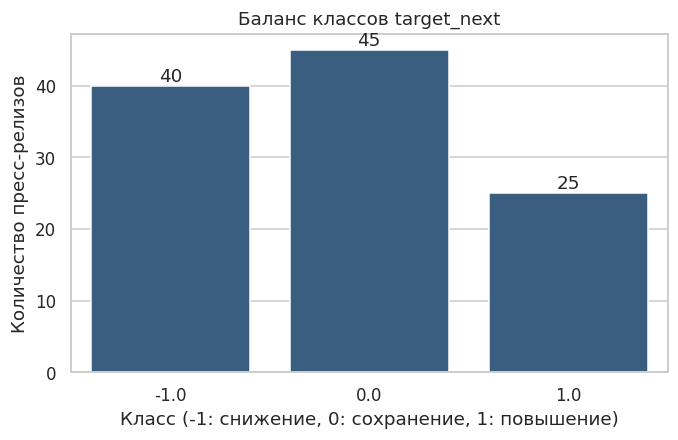

In [92]:
class_counts = df_clean_w_target['target_next'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=class_counts.index.astype(str), y=class_counts.values, color='#2E5E8C', ax=ax)
ax.set_title("Баланс классов target_next")
ax.set_xlabel("Класс (-1: снижение, 0: сохранение, 1: повышение)")
ax.set_ylabel("Количество пресс-релизов")

for p, v in zip(ax.patches, class_counts.values):
    ax.annotate(v, (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom')

plt.show()

Классы не являются идеально сбалансированными, наблюдается умеренный дисбаланс. Самый частый класс (0) встречается более чем в два раза чаще самого редкого класса (1).

Оценивать качество модели только по метрике accuracy в данном случае будет некорректно. Обязательно нужно смотреть на Macro F1-score, Recall и Precision.



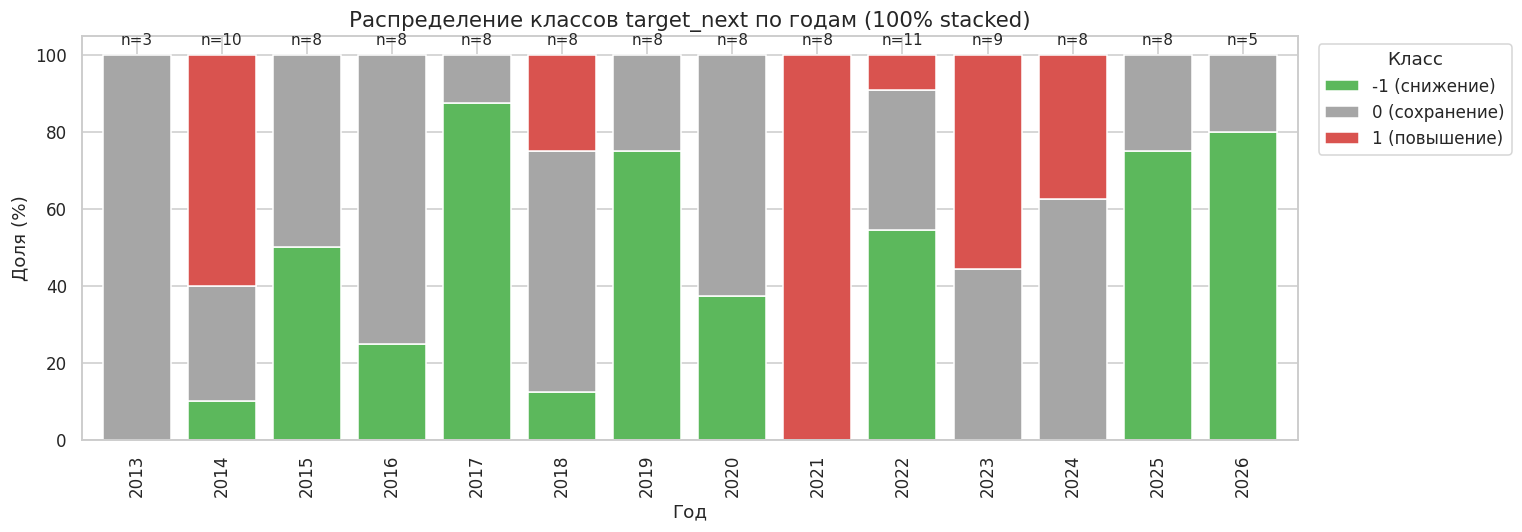

In [93]:
df_clean_w_target['year'] = df_clean_w_target['date'].dt.year
ct = pd.crosstab(df_clean_w_target['year'], df_clean_w_target['target_next'])
ct_norm = ct.div(ct.sum(axis=1), axis=0) * 100
colors = ['#5cb85c', '#a6a6a6', '#d9534f']

fig, ax = plt.subplots(figsize=(14, 5))
ct_norm.plot(kind='bar', stacked=True, color=colors, ax=ax, width=0.8)

ax.set_title('Распределение классов target_next по годам (100% stacked)', fontsize=14)
ax.set_xlabel('Год', fontsize=12)
ax.set_ylabel('Доля (%)', fontsize=12)
ax.legend(title='Класс', labels=['-1 (снижение)', '0 (сохранение)', '1 (повышение)'],
          bbox_to_anchor=(1.01, 1), loc='upper left')

for i, year in enumerate(ct.index):
    total = ct.loc[year].sum()
    ax.text(i, 102, f'n={total}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

Этот график помогает увидеть временной сдвиг: модель, обученная на ранних годах, может хуже работать на более поздних, если поведение ЦБ и формулировки пресс-релизов меняются. Поэтому для проверки качества предпочтительно временное разделение на train/test, а не случайное перемешивание.


/tmp/ipykernel_3485/3526768347.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


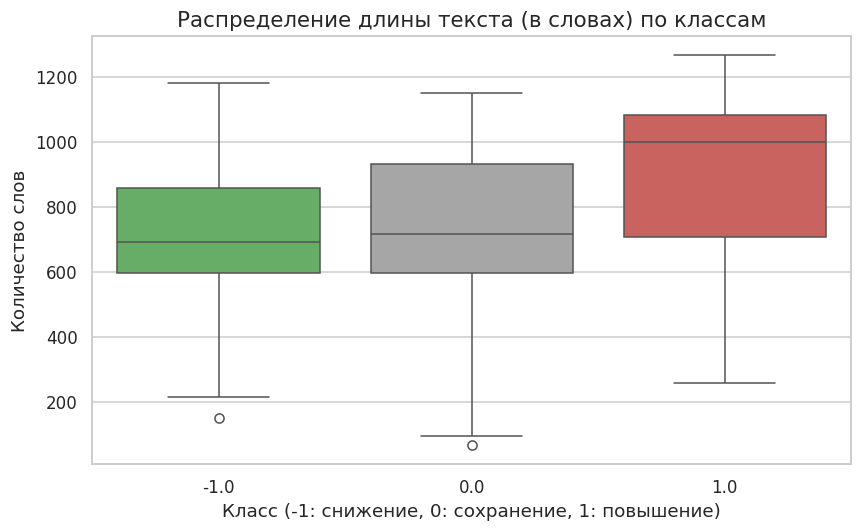

Медианная длина текста (в словах) по классам:
target_next
-1.0     690.5
 0.0     717.0
 1.0    1000.0
Name: len_words, dtype: float64


In [94]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=df_clean_w_target,
    x='target_next',
    y='len_words',
    palette=colors,
    ax=ax
)

ax.set_title('Распределение длины текста (в словах) по классам', fontsize=14)
ax.set_xlabel('Класс (-1: снижение, 0: сохранение, 1: повышение)', fontsize=12)
ax.set_ylabel('Количество слов', fontsize=12)

plt.tight_layout()
plt.show()

print("Медианная длина текста (в словах) по классам:")
print(df_clean_w_target.groupby('target_next')['len_words'].median())

Длина текста не различает классы снижения и сохранения, но является значимым признаком для класса повышения

/tmp/ipykernel_3485/2769832372.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


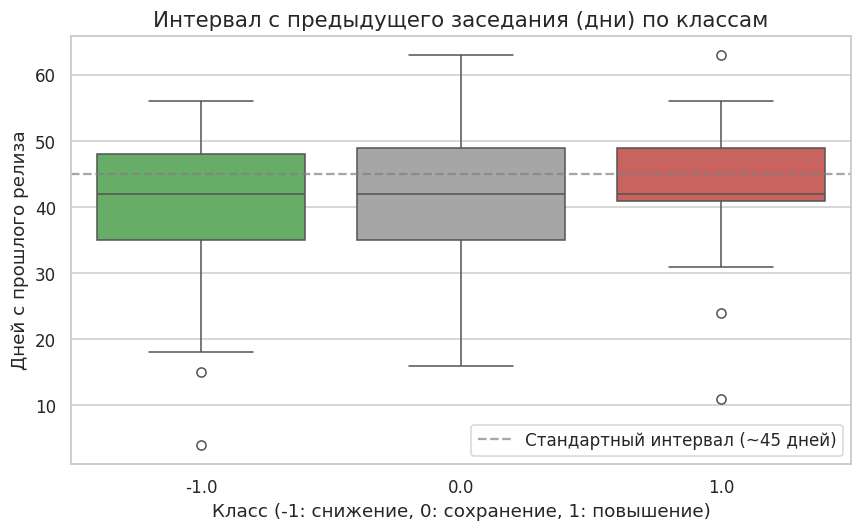

In [95]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=df_clean_w_target,
    x='target_next',
    y='days_since_prev',
    palette=colors,
    ax=ax
)

ax.set_title('Интервал с предыдущего заседания (дни) по классам', fontsize=14)
ax.set_xlabel('Класс (-1: снижение, 0: сохранение, 1: повышение)', fontsize=12)
ax.set_ylabel('Дней с прошлого релиза', fontsize=12)

# Добавим горизонтальную линию стандартного интервала (~45 дней)
ax.axhline(45, color='gray', linestyle='--', alpha=0.7, label='Стандартный интервал (~45 дней)')
ax.legend()

plt.tight_layout()
plt.show()

Короткие интервалы чаще встречаются перед изменением ставки.

### Семантический анализ

Семантический анализ здесь основан на TF-IDF: каждому слову или биграмме присваивается вес с учётом частоты в документе и редкости во всём корпусе. Затем для каждого класса вычисляется разница между средним TF-IDF внутри класса и вне него.

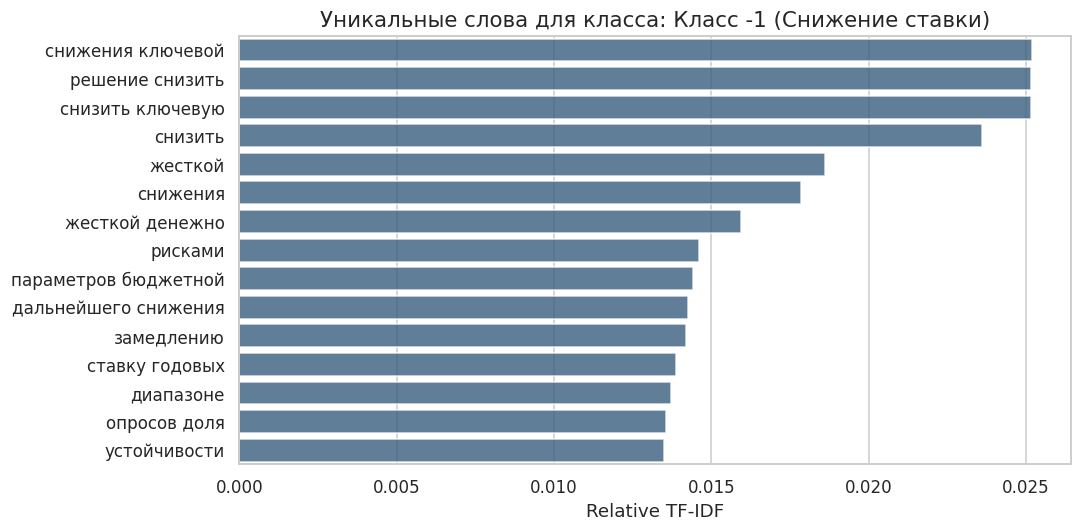

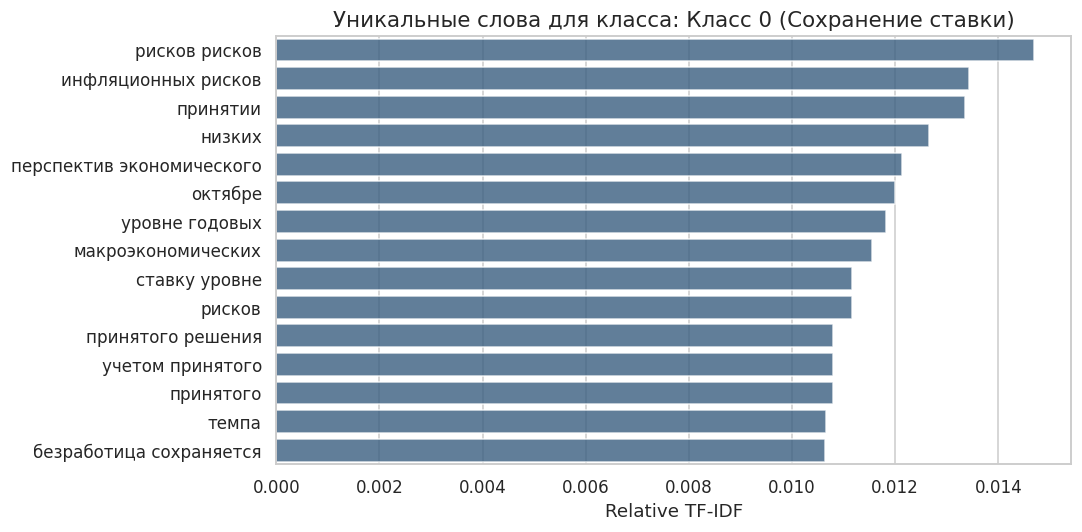

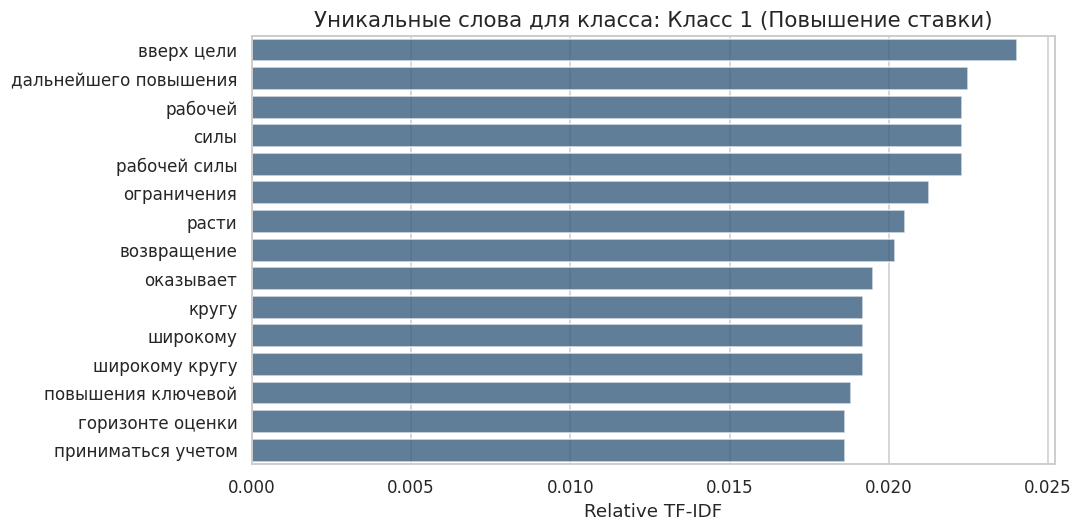

In [100]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Расширенный список стоп-слов (добавляем предлоги и местоимения)
basic_stopwords = ['на', 'по', 'до', 'в', 'с', 'за', 'из', 'от', 'для', 'при', 'об', 'о', 'не', 'что', 'как', 'это', 'или', 'но', 'а', 'же', 'ли', 'бы', 'его', 'ее', 'их', 'над', 'под', 'без']
custom_stop_words = [
    'россии', 'россия', 'банка', 'банк', 'года', 'год', 'также', 'этом', 'который',
    'которая', 'которые', 'будет', 'были', 'более', 'менее', 'может', 'только',
    'через', 'после', 'чтобы', 'если', 'своих', 'своей', 'около', 'связи', 'всего',
    'набиуллиной', 'эльвиры', 'председателя', 'совета', 'директоров', 'заседания',
    'пресс', 'службу', 'ссылку', 'pdf', 'сохранить', 'копировать', 'материала'
] + basic_stopwords

# 2. Настраиваем векторизатор
# token_pattern — оставляем ТОЛЬКО кириллицу длиной от 4 букв (это уберет числа и предлоги)
vectorizer = TfidfVectorizer(
    max_features=3000,
    ngram_range=(1, 2),
    stop_words=custom_stop_words,
    token_pattern=r'(?u)\b[А-Яа-яЁё]{4,}\b',
    sublinear_tf=True
)

# Векторизуем
X = vectorizer.fit_transform(df_clean_w_target['text_clean'])
feature_names = vectorizer.get_feature_names_out()

# 3. Вычисляем уникальность (Relative TF-IDF)
# Для каждого класса считаем: (средний TF-IDF в классе) - (средний TF-IDF в остальных)
classes = [-1, 0, 1]
class_titles = {
    -1: 'Класс -1 (Снижение ставки)',
     0: 'Класс 0 (Сохранение ставки)',
     1: 'Класс 1 (Повышение ставки)'
}

for cls in classes:
    idx_class = df_clean_w_target[df_clean_w_target['target_next'] == cls].index
    idx_other = df_clean_w_target[df_clean_w_target['target_next'] != cls].index

    # Средний TF-IDF для этого класса и для остальных
    mean_tfidf_class = np.asarray(X[idx_class].mean(axis=0)).flatten()
    mean_tfidf_other = np.asarray(X[idx_other].mean(axis=0)).flatten()

    # Разница (насколько слово более характерно для этого класса)
    relative_importance = mean_tfidf_class - mean_tfidf_other

    # Находим топ-15 уникальных слов
    top_indices = relative_importance.argsort()[-15:][::-1]
    top_words = [feature_names[i] for i in top_indices]
    top_scores = [relative_importance[i] for i in top_indices]

    # Строим график
    plt.figure(figsize=(10, 5))
    sns.barplot(x=top_scores, y=top_words, color='#2E5E8C', alpha=0.8)
    plt.title(f'Уникальные слова для класса: {class_titles[cls]}', fontsize=14)
    plt.xlabel('Relative TF-IDF', fontsize=12)
    plt.ylabel('')
    plt.tight_layout()
    plt.show()


Результаты TF-IDF показывают, что пресс-релизы ЦБ содержат характерные для каждого класса лексические и тематические особенности. Для класса снижения ставки выделяются формулировки о смягчении денежно-кредитной политики и замедлении инфляции, для класса повышения — упоминания проинфляционных факторов, ограничений на рынке труда и рисков роста цен. Класс сохранения ставки характеризуется более общими формулировками об экономических условиях и инфляционных рисках.